# KM6312 Food Delivery Data Analysis

This notebook follows a step-by-step classroom workflow. Keep the notebook and the original CSV in the same folder and run the cells in order. It covers data preparation, the three research questions, sensitivity checks, and model interpretation using PDP and ICE.

## 1. Load the data
Inspect the dataset dimensions and the first three rows.

In [1]:
import pandas as pd
from sklearn import set_config
set_config(display='text')
from sklearn.model_selection import train_test_split

data = pd.read_csv('food_delivery_analytics_cleaned.csv')
print('Rows and columns:', data.shape)
data.head(3)

Rows and columns: (15000, 30)


,order_id,city_tier,customer_age,customer_loyalty_score,order_hour,order_day_of_week,order_month,delivery_distance_km,preparation_time_minutes,delivery_time_minutes,...,final_amount_paid,number_of_items,cancellation_flag,delayed_delivery_flag,refund_flag,promo_code_used,premium_customer_flag,festival_or_weekend_flag,delivery_partner_experience_years,delivery_efficiency_score
0,5a87c6ab-e4a8-44ef-8852-f7a63e3b3943,2,21,4.957522,20,6,6,14.117144,23,76,...,111.563784,4,False,False,True,False,False,True,9,71.1
1,8eab78a5-a5c5-41d7-9a5f-5779ee5f2d3d,1,63,38.744721,0,2,2,9.177354,16,34,...,116.059264,7,False,False,False,True,False,False,12,100.0
2,1338cc5b-e5cf-419f-a7c9-4a2577608715,1,68,45.170997,9,2,11,34.753921,41,152,...,111.708170,12,False,False,False,False,False,False,10,34.4


## 2. Check duplicates and missing values
Inspect data quality before deciding how to handle missing values. Do not automatically remove every row containing a missing value.

In [2]:
print('Duplicate rows:', data.duplicated().sum())
print('Duplicate order IDs:', data['order_id'].duplicated().sum())
missing = data.isna().sum()
missing[missing > 0]

Duplicate rows: 0
Duplicate order IDs: 0


delivery_partner_rating    150
customer_rating            150
tip_amount                 150
dtype: int64

## 3. Select non-cancelled orders
Use a copy to preserve the original data. The cancellation flag is used only to select the main analysis cohort and is excluded from the predictors.

In [3]:
main = data[data['cancellation_flag'] == False].copy()
print('Original orders:', len(data))
print('Non-cancelled orders:', len(main))

Original orders: 15000
Non-cancelled orders: 12997


## 4. Select the predictors
Retain 11 operational features and check the selected features and targets for missing values. Actual delivery time, the efficiency score, and estimated delivery time are excluded from the primary model inputs.

In [4]:
features = [
    'city_tier', 'order_hour', 'order_day_of_week', 'order_month',
    'delivery_distance_km', 'preparation_time_minutes',
    'traffic_level_score', 'weather_severity_score',
    'delivery_partner_experience_years', 'number_of_items',
    'festival_or_weekend_flag'
]
main[features + ['delivery_time_minutes', 'delivery_efficiency_score']].isna().sum()

city_tier                            0
order_hour                           0
order_day_of_week                    0
order_month                          0
delivery_distance_km                 0
preparation_time_minutes             0
traffic_level_score                  0
weather_severity_score               0
delivery_partner_experience_years    0
number_of_items                      0
festival_or_weekend_flag             0
delivery_time_minutes                0
delivery_efficiency_score            0
dtype: int64

## Additional data checks used in the report

Inspect the selected-variable ranges and count orders whose recorded delivery time is shorter than preparation time. Keep these records because the source does not define the starting points of the two durations clearly. The count uses all 15,000 records; the descriptive table uses the non-cancelled analysis cohort.

In [5]:
print('Orders with delivery time shorter than preparation time:',
      (data['delivery_time_minutes'] < data['preparation_time_minutes']).sum())
main[features + ['delivery_time_minutes', 'delivery_efficiency_score']].describe().round(2)

Orders with delivery time shorter than preparation time: 112


,city_tier,order_hour,order_day_of_week,order_month,delivery_distance_km,preparation_time_minutes,traffic_level_score,weather_severity_score,delivery_partner_experience_years,number_of_items,delivery_time_minutes,delivery_efficiency_score
count,12997.00,12997.00,12997.00,12997.00,12997.00,12997.00,12997.00,12997.00,12997.00,12997.00,12997.00,12997.00
mean,2.25,11.48,3.15,6.49,20.15,32.70,4.98,4.92,8.06,6.51,93.88,59.56
std,0.83,6.92,1.81,3.45,11.52,16.18,2.80,2.89,4.30,3.44,33.50,18.01
min,1.00,0.00,1.00,1.00,0.10,5.00,1.00,0.00,1.00,1.00,10.00,1.90
25%,2.00,6.00,1.00,3.00,10.17,19.00,2.40,2.40,4.00,4.00,68.00,46.80
50%,3.00,11.00,3.00,7.00,20.30,33.00,4.90,4.80,8.00,7.00,94.00,59.60
75%,3.00,18.00,5.00,9.00,29.98,47.00,7.40,7.50,12.00,10.00,119.00,72.30
max,3.00,23.00,6.00,12.00,40.00,60.00,10.00,10.00,15.00,12.00,180.00,100.00


## 5. Split the training and test sets
Use random_state=42 to reproduce the same split. The regression target is actual delivery time.

In [6]:
train, test = train_test_split(main, test_size=0.2, random_state=42)
X_train = train[features]
X_test = test[features]
y_time_train = train['delivery_time_minutes']
y_time_test = test['delivery_time_minutes']
print('Training orders:', len(train), '| Test orders:', len(test))

Training orders: 10397 | Test orders: 2600


## 6. Create the low-efficiency labels
Calculate the 25th-percentile cutoff using only the training set, then apply it to the test set. Low efficiency is labelled 1 and other orders 0. Tied scores can make the positive-class share slightly greater than 25%.

In [7]:
threshold = train['delivery_efficiency_score'].quantile(0.25)
y_low_train = (train['delivery_efficiency_score'] <= threshold).astype(int)
y_low_test = (test['delivery_efficiency_score'] <= threshold).astype(int)
print('Low-efficiency threshold:', threshold)

pd.DataFrame({
    'Orders': [len(train), len(test)],
    'Low-efficiency orders': [y_low_train.sum(), y_low_test.sum()],
    'Low-efficiency (%)': [y_low_train.mean() * 100, y_low_test.mean() * 100]
}, index=['Training', 'Test']).round(2)

Low-efficiency threshold: 46.9


,Orders,Low-efficiency orders,Low-efficiency (%)
Training,10397,2603,25.04
Test,2600,669,25.73


## Conventions for the remaining analysis

- RQ1 uses the training set, train, for exploratory analysis. The predictive models use X_train, X_test, and the corresponding targets defined above.
- The primary scenario assumes that actual preparation time is known, delivery is not yet complete, and traffic, weather, and the other inputs are available at that point. The CSV does not record when each field was collected. A sensitivity check removes preparation time to examine an earlier information scenario.
- Categorical encoding and scaling are fitted within the modelling stage as required, rather than in advance.
- The efficiency score has a fixed formula structure and defines relative low efficiency within this synthetic dataset. Interpret weekday codes and the start and end points of the time variables cautiously.

# Step 3: RQ1 Exploratory Analysis

What operational, environmental, and delivery-partner factors are associated with delivery time and delivery efficiency? This section uses only the 10,397 training records and does not fit predictive models. Figures are saved as PNG files for the report.

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
fig_dir = Path('outputs/step03')
fig_dir.mkdir(parents=True, exist_ok=True)
targets = ['delivery_time_minutes', 'delivery_efficiency_score']
target_labels = ['Delivery time (minutes)', 'Efficiency score']
train[targets].describe().round(2)

,delivery_time_minutes,delivery_efficiency_score
count,10397.00,10397.00
mean,93.91,59.59
std,33.55,18.00
min,10.00,1.90
25%,68.00,46.90
50%,94.00,59.60
75%,120.00,72.20
max,180.00,100.00


## 7. Distributions of delivery time and efficiency

Inspect the ranges and distributions of the two outcomes. The dashed line marks the low-efficiency cutoff determined from the training set.

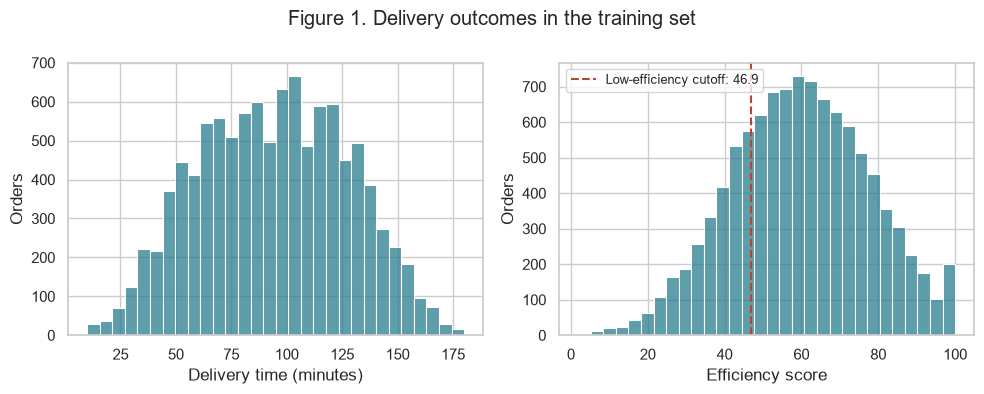

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, column, label in zip(axes, targets, target_labels):
    sns.histplot(data=train, x=column, bins=30, color='#287c8e', ax=ax)
    ax.set(xlabel=label, ylabel='Orders')
axes[1].axvline(threshold, color='#b34732', linestyle='--', label=f'Low-efficiency cutoff: {threshold}')
axes[1].legend(fontsize=9)
fig.suptitle('Figure 1. Delivery outcomes in the training set')
plt.tight_layout()
plt.savefig(fig_dir / 'Fig1_Outcome_Distributions.png', dpi=300)
plt.show()

## 8. Correlations between operational factors and outcomes

Use Pearson correlations for continuous variables, counts, and the binary flag. City tier and time codes are treated as categories and examined through grouped summaries in Section 12; their numerical codes are not interpreted as continuous measurements.

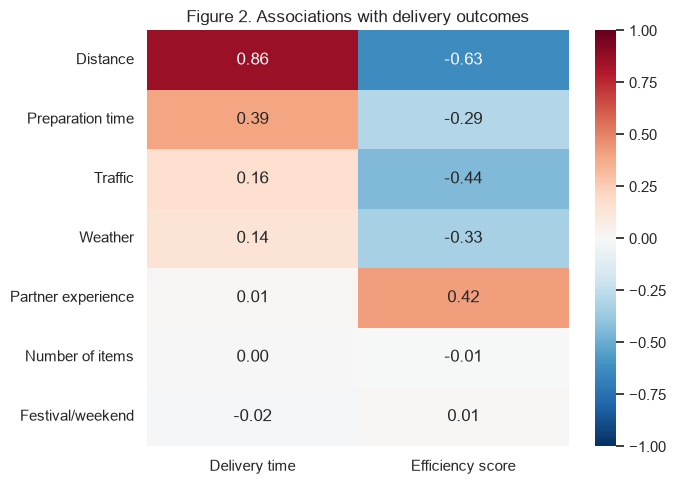

,Delivery time,Efficiency score
Distance,0.864,-0.632
Preparation time,0.393,-0.293
Traffic,0.164,-0.440
Weather,0.135,-0.331
Partner experience,0.013,0.420
Number of items,0.003,-0.006
Festival/weekend,-0.019,0.009


In [10]:
factors = ['delivery_distance_km', 'preparation_time_minutes',
           'traffic_level_score', 'weather_severity_score',
           'delivery_partner_experience_years', 'number_of_items',
           'festival_or_weekend_flag']
corr = train[factors + targets].corr().loc[factors, targets]
corr.index = ['Distance', 'Preparation time', 'Traffic', 'Weather',
              'Partner experience', 'Number of items', 'Festival/weekend']
corr.columns = ['Delivery time', 'Efficiency score']
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0)
plt.title('Figure 2. Associations with delivery outcomes')
plt.tight_layout()
plt.savefig(fig_dir / 'Fig2_Outcome_Correlations.png', dpi=300)
plt.show()
corr.round(3)

## 9. Distance, preparation time, and actual delivery time

The scatterplots include all training orders. Transparency helps show overlapping observations. The plotted relationships are observed associations.

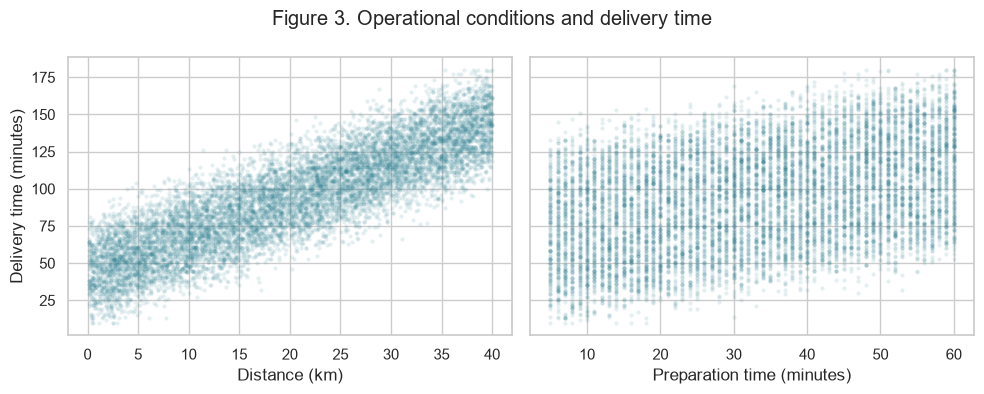

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, column, label in zip(axes, ['delivery_distance_km', 'preparation_time_minutes'], ['Distance (km)', 'Preparation time (minutes)']):
    sns.scatterplot(data=train, x=column, y='delivery_time_minutes', s=9, alpha=0.12, linewidth=0, color='#287c8e', ax=ax)
    ax.set(xlabel=label, ylabel='Delivery time (minutes)')
fig.suptitle('Figure 3. Operational conditions and delivery time')
plt.tight_layout()
plt.savefig(fig_dir / 'Fig3_Distance_Preparation_Time.png', dpi=300)
plt.show()

## 10. Grouped comparisons of traffic and weather

Divide each score into training-set quartiles, labelled Q1 to Q4 from low to high. The plots show group means. Grouped trends do not establish causal relationships.

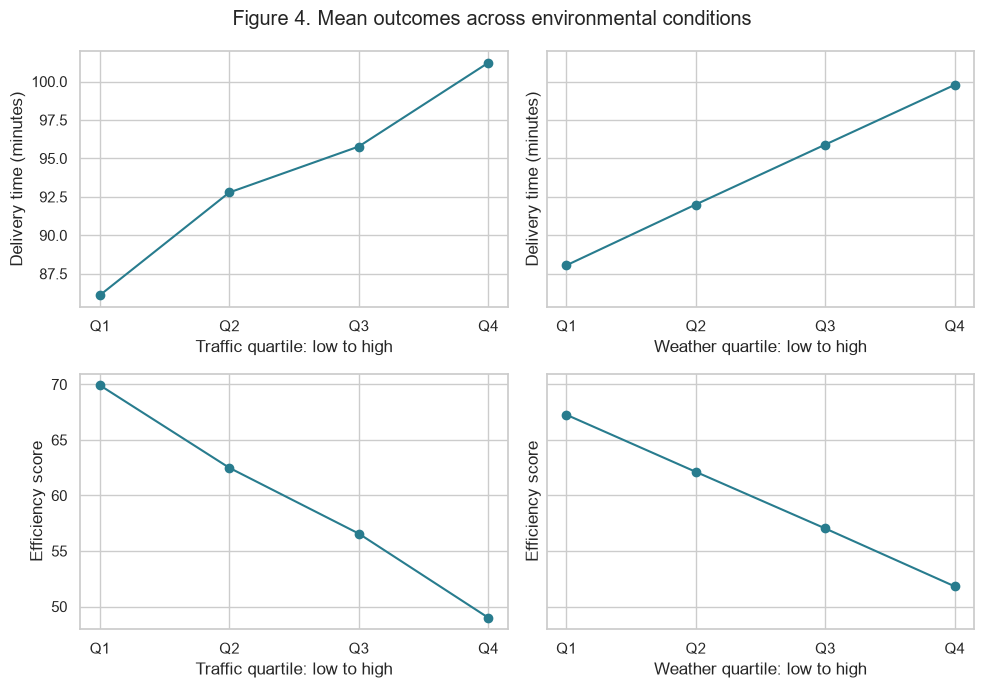

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey='row')
for j, (column, label) in enumerate([('traffic_level_score', 'Traffic'), ('weather_severity_score', 'Weather')]):
    groups = pd.qcut(train[column], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
    means = train.groupby(groups, observed=True)[targets].mean()
    for i, target in enumerate(targets):
        axes[i, j].plot(means.index.astype(str), means[target], marker='o', color='#287c8e')
        axes[i, j].set(xlabel=f'{label} quartile: low to high', ylabel=target_labels[i])
fig.suptitle('Figure 4. Mean outcomes across environmental conditions')
plt.tight_layout()
plt.savefig(fig_dir / 'Fig4_Environmental_Groups.png', dpi=300)
plt.show()

## 11. Partner experience and the two outcomes

Divide experience into four groups and compare delivery time and efficiency using boxplots. Each box spans the 25th to 75th percentiles, and the line inside marks the median.

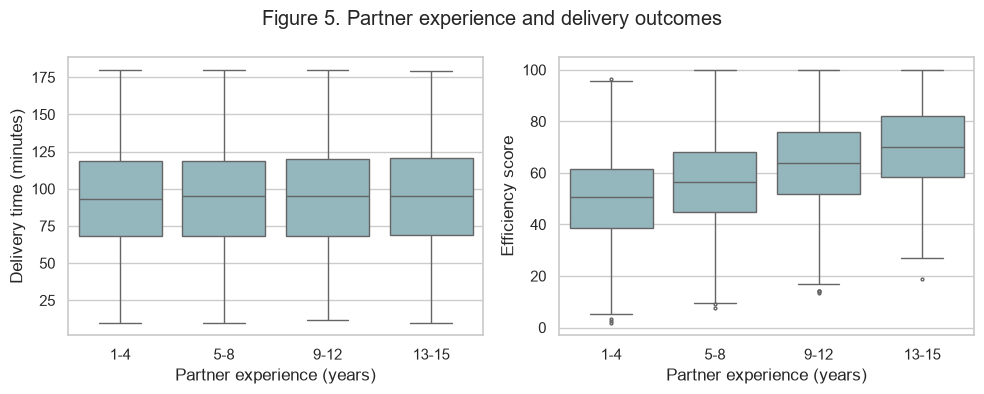

,delivery_time_minutes,delivery_efficiency_score
experience_group,,
1-4,93.13,50.01
5-8,94.06,56.50
9-12,94.06,63.93
13-15,94.54,70.13


In [13]:
eda = train.copy()
eda['experience_group'] = pd.cut(eda['delivery_partner_experience_years'], bins=[0, 4, 8, 12, 15], labels=['1-4', '5-8', '9-12', '13-15'])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, target, label in zip(axes, targets, target_labels):
    sns.boxplot(data=eda, x='experience_group', y=target, color='#8dbbc5', ax=ax, fliersize=2)
    ax.set(xlabel='Partner experience (years)', ylabel=label)
fig.suptitle('Figure 5. Partner experience and delivery outcomes')
plt.tight_layout()
plt.savefig(fig_dir / 'Fig5_Partner_Experience.png', dpi=300)
plt.show()
eda.groupby('experience_group', observed=True)[targets].mean().round(2)

## 12. City tier, order timing, and other conditions

Use groupby to inspect category counts and mean outcomes. Hours, weekdays, and months are shown using their original codes. Small differences in sample means do not establish stable patterns.

In [14]:
for column in ['city_tier', 'order_hour', 'order_day_of_week', 'order_month', 'festival_or_weekend_flag', 'number_of_items']:
    print(column)
    display(train.groupby(column).agg(Orders=('order_id', 'size'), Mean_time=('delivery_time_minutes', 'mean'), Mean_efficiency=('delivery_efficiency_score', 'mean')).round(2))

city_tier


,Orders,Mean_time,Mean_efficiency
city_tier,,,
1,2546,93.98,59.47
2,2640,92.98,59.99
3,5211,94.36,59.44


order_hour


,Orders,Mean_time,Mean_efficiency
order_hour,,,
0,441,94.60,59.32
1,445,92.02,60.23
2,447,91.40,61.08
3,438,91.20,60.98
4,426,93.19,60.30
5,421,95.14,58.59
6,453,91.79,59.90
7,431,94.52,59.29
8,429,93.90,59.68


order_day_of_week


,Orders,Mean_time,Mean_efficiency
order_day_of_week,,,
1,2951,93.61,59.55
2,1471,94.56,59.24
3,1501,93.56,60.03
4,1447,94.72,59.27
5,1516,94.81,59.46
6,1511,92.55,59.98


... (2 outputs left out)

festival_or_weekend_flag


,Orders,Mean_time,Mean_efficiency
festival_or_weekend_flag,,,
False,8240,94.24,59.50
True,2157,92.69,59.91


number_of_items


,Orders,Mean_time,Mean_efficiency
number_of_items,,,
1,829,93.96,59.46
2,879,92.39,60.78
3,872,95.25,58.92
4,819,93.66,59.38
5,893,93.35,60.04
6,855,94.29,59.07
7,944,95.10,59.31
8,856,93.49,59.84
9,840,93.07,60.23


## Interpretation of RQ1 results

This section uses the 10,397 non-cancelled orders in the training set.

### Main associations

- Distance: Pearson r = 0.864 with delivery time and r = -0.632 with the efficiency score.
- Preparation time: Pearson r = 0.393 with delivery time and r = -0.293 with the efficiency score.
- Traffic: Pearson r = 0.164 with delivery time and r = -0.440 with the efficiency score.
- Weather: Pearson r = 0.135 with delivery time and r = -0.331 with the efficiency score.
- Partner experience: Pearson r = 0.013 with delivery time and r = 0.420 with the efficiency score.

### Grouped comparisons

- Delivery distance: the lowest quartile has a mean delivery time of 56.30 minutes and a mean efficiency score of 74.43; the highest quartile has corresponding means of 131.36 minutes and 44.94.
- Preparation time: the lowest quartile has a mean delivery time of 76.71 minutes and a mean efficiency score of 66.34; the highest quartile has corresponding means of 111.46 minutes and 52.60.
- Traffic score: the lowest quartile has a mean delivery time of 86.10 minutes and a mean efficiency score of 69.93; the highest quartile has corresponding means of 101.22 minutes and 49.00.
- Weather severity: the lowest quartile has a mean delivery time of 88.04 minutes and a mean efficiency score of 67.28; the highest quartile has corresponding means of 99.78 minutes and 51.82.

The 1-4-year and 13-15-year experience groups have mean delivery times of 93.13 and 94.54 minutes, respectively, and mean efficiency scores of 50.01 and 70.13.

### Answer to RQ1 and interpretation limits

Distance and preparation time are positively associated with delivery time. Traffic and weather are also associated with time and efficiency. Experience is much more strongly associated with the efficiency score than with delivery time. City tier and time codes are described through grouped summaries; mean differences alone do not establish causality or statistical significance.

The efficiency score can be reproduced using a fixed formula involving actual delivery time, traffic, weather, and experience, with a positive weight for experience. Therefore, the positive association between experience and efficiency does not demonstrate that more experience makes deliveries faster. These findings describe associations in synthetic data. This section does not test causal effects or evaluate predictive models.

# Step 4: RQ2 Delivery-Time Prediction

Use the original 11 features, 10,397 training records, and 2,600 test records. Compare models through five-fold cross-validation within the training set, then evaluate the specified models on the test set. Parameters are fixed in advance and are not adjusted using test results. Select the main diagnostic model using cross-validation MAE.

## 13. Encoding and scaling

Treat city tier and time codes as categorical variables. Standardise numeric features and pass through the festival/weekend flag. Include preprocessing within each model pipeline so that it is fitted only on the current training fold during cross-validation. These library functions keep training and test transformations consistent.

In [15]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

categories = ['city_tier', 'order_hour', 'order_day_of_week', 'order_month']
numeric = [c for c in features if c not in categories + ['festival_or_weekend_flag']]
preprocess = ColumnTransformer([
    ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categories),
    ('numeric', StandardScaler(), numeric),
    ('weekend', 'passthrough', ['festival_or_weekend_flag'])
])

## 14. Define four comparison models

The mean baseline always predicts the mean delivery time of its training sample. Ridge is regularised linear regression. Random forest and gradient boosting test whether more flexible models improve performance. Fix the seeds for random procedures.

In [16]:
models = {
    'Mean baseline': DummyRegressor(strategy='mean'),
    'Ridge': Ridge(alpha=1.0),
    'Random forest': RandomForestRegressor(n_estimators=150, min_samples_leaf=3, random_state=42, n_jobs=1),
    'Gradient boosting': HistGradientBoostingRegressor(max_iter=200, max_leaf_nodes=15, learning_rate=0.08, l2_regularization=1.0, early_stopping=True, random_state=42)
}
models = {name: make_pipeline(clone(preprocess), model) for name, model in models.items()}

## 15. Five-fold cross-validation within the training set

MAE is the mean absolute error. RMSE gives more weight to larger errors. Both are measured in minutes, and lower values are better. Higher R-squared indicates more variation explained relative to a mean-prediction benchmark. Model selection uses mean MAE across the five folds.

In [17]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}
cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_time_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({'Model': name, 'CV MAE': -scores['test_mae'].mean(),
                    'MAE SD': scores['test_mae'].std(),
                    'CV RMSE': -scores['test_rmse'].mean(), 'CV R2': scores['test_r2'].mean()})
cv_results = pd.DataFrame(cv_rows)
selected_name = cv_results.sort_values('CV MAE').iloc[0]['Model']
print('Model selected using training CV:', selected_name)
cv_results.round(3)

Model selected using training CV: Ridge


,Model,CV MAE,MAE SD,CV RMSE,CV R2
0,Mean baseline,28.022,0.445,33.546,-0.000
1,Ridge,6.504,0.095,8.151,0.941
2,Random forest,6.900,0.083,8.636,0.934
3,Gradient boosting,6.698,0.087,8.389,0.937


## 16. Held-out test evaluation and the existing ETA benchmark

Fit each model on the complete training set, then evaluate it on the same test set. Use estimated_delivery_time only as a separate benchmark, never as a primary model input. The CSV does not document when or how this ETA was generated. The comparison therefore concerns numerical errors and does not establish an improvement in real operations.

In [18]:
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_time_train)
    predictions[name] = model.predict(X_test)
predictions['Existing ETA'] = test['estimated_delivery_time'].to_numpy()
rows = []
for name, predicted in predictions.items():
    rows.append({'Model': name, 'MAE': mean_absolute_error(y_time_test, predicted),
                 'RMSE': mean_squared_error(y_time_test, predicted) ** 0.5,
                 'R2': r2_score(y_time_test, predicted)})
regression_results = pd.DataFrame(rows)
regression_results.round(3)

,Model,MAE,RMSE,R2
0,Mean baseline,27.698,33.287,-0.000
1,Ridge,6.309,7.952,0.943
2,Random forest,6.613,8.330,0.937
3,Gradient boosting,6.539,8.231,0.939
4,Existing ETA,6.289,7.933,0.943


## 17. Compare model performance

Compare the five sets of results, including the two benchmarks. Assess the value of model complexity using both the numerical differences and model interpretability.

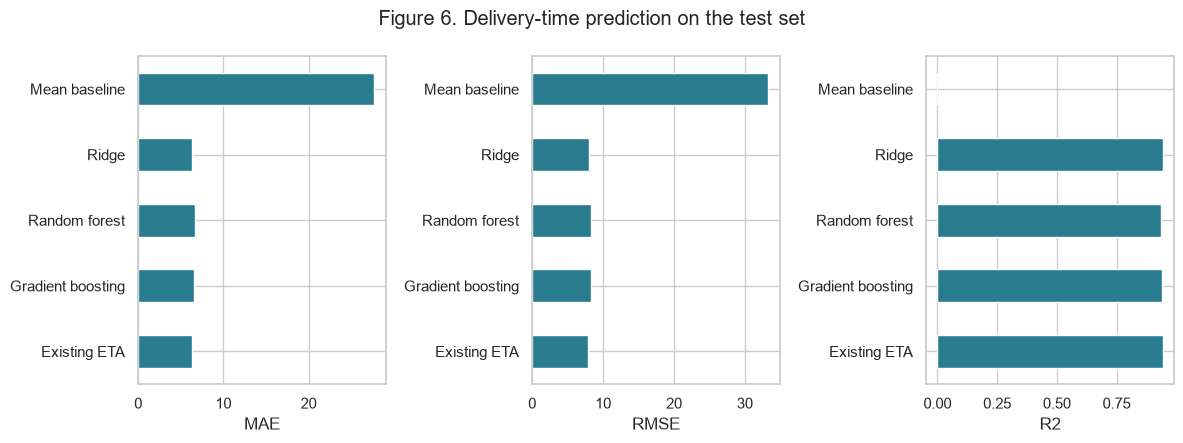

In [19]:
reg_dir = Path('outputs/step04')
reg_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'R2']):
    regression_results.set_index('Model')[metric].plot.barh(ax=ax, color='#287c8e')
    ax.invert_yaxis()
    ax.set(xlabel=metric, ylabel='')
fig.suptitle('Figure 6. Delivery-time prediction on the test set')
plt.tight_layout()
plt.savefig(reg_dir / 'Fig6_Regression_Comparison.png', dpi=300)
plt.show()

pd.DataFrame({'order_id': test['order_id'], 'actual_delivery_time': y_time_test,
              **predictions}).to_csv(reg_dir / 'RQ2_Test_Predictions.csv', index=False)

## 18. Actual versus predicted delivery time

Show the model selected through cross-validation alongside the existing ETA. The dashed line represents perfect agreement between predictions and actual values; points closer to the line indicate smaller errors.

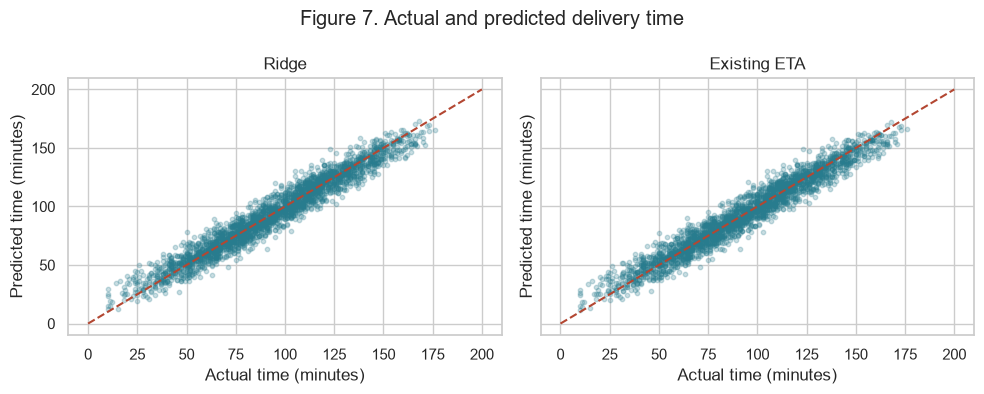

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, name in zip(axes, [selected_name, 'Existing ETA']):
    ax.scatter(y_time_test, predictions[name], s=10, alpha=0.25, color='#287c8e')
    ax.plot([0, 200], [0, 200], linestyle='--', color='#b34732')
    ax.set(xlabel='Actual time (minutes)', ylabel='Predicted time (minutes)', title=name)
fig.suptitle('Figure 7. Actual and predicted delivery time')
plt.tight_layout()
plt.savefig(reg_dir / 'Fig7_Actual_vs_Predicted.png', dpi=300)
plt.show()

## 19. Error distribution and error patterns

Define error as actual minus predicted time. Positive values indicate underprediction and negative values indicate overprediction. Use the histogram to inspect overall bias and the scatterplot to inspect whether errors vary with predicted time.

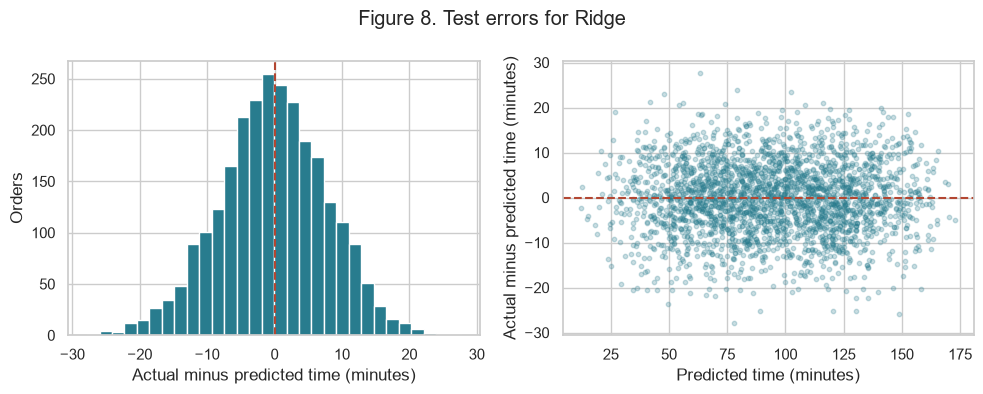

count    2600.000
mean       -0.251
std         7.950
min       -27.816
25%        -5.388
50%        -0.198
75%         5.111
max        27.668
Name: delivery_time_minutes, dtype: float64

In [21]:
residuals = y_time_test - predictions[selected_name]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(residuals, bins=30, color='#287c8e')
axes[0].axvline(0, linestyle='--', color='#b34732')
axes[0].set(xlabel='Actual minus predicted time (minutes)', ylabel='Orders')
axes[1].scatter(predictions[selected_name], residuals, s=10, alpha=0.25, color='#287c8e')
axes[1].axhline(0, linestyle='--', color='#b34732')
axes[1].set(xlabel='Predicted time (minutes)', ylabel='Actual minus predicted time (minutes)')
fig.suptitle(f'Figure 8. Test errors for {selected_name}')
plt.tight_layout()
plt.savefig(reg_dir / 'Fig8_Regression_Errors.png', dpi=300)
plt.show()
residuals.describe().round(3)

## Interpretation of RQ2 results

Five-fold cross-validation uses the 10,397 training records. The held-out test set contains 2,600 records. Model parameters are fixed in advance and are not tuned using test results.

The model selected by mean training CV MAE is **Ridge**. Its test MAE is **6.309 minutes**, RMSE is **7.952 minutes**, and R-squared is **0.943**.
The mean baseline has an MAE of 27.698 minutes. The selected model reduces MAE by approximately 77.2% relative to this baseline.
The existing ETA in the CSV has an MAE of 6.289 minutes. The small numerical difference does not demonstrate a practical improvement by our model. The generation time and algorithm of the existing ETA are unknown.

The selected model has a mean signed error of -0.251 minutes. Absolute errors are at most 10 minutes for 79.0% of test orders, and the 90th percentile of absolute error is 13.00 minutes. These are test-error summaries, not calibrated prediction intervals for future orders.

### Answer to RQ2 and interpretation limits

Actual delivery time can be predicted with relatively small errors in this synthetic dataset under the specified information scenario. Use the cross-validation and test tables to assess the added value of more complex models; do not assume that complexity necessarily improves performance.

These primary results assume that actual preparation time is known. Step 6 examines an earlier information scenario by removing preparation time. A random split does not provide external validation on future periods, other platforms, or real operations.

# Step 5: RQ3 Identify Low-Efficiency Orders

Keep the original split and the efficiency cutoff of 46.9 determined from the outer training set. Low efficiency is the positive class, labelled 1, and represents approximately 25% of training orders. Five-fold validation compares models within the training set using this fixed label definition. Select the model by mean F1. Classification uses the default 0.5 probability threshold; do not adjust thresholds or parameters using test results. Actual delivery time, the efficiency score, and the existing ETA are excluded from the inputs.

## 20. Define the classification models

The majority-class baseline always predicts the other class. Logistic regression, random forest, and gradient boosting use the same inputs and preprocessing rules as RQ2. Reuse the unfitted preprocessing specification and create an independent copy for each model.

In [22]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, confusion_matrix
from sklearn.inspection import permutation_importance

clf_models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic': LogisticRegression(C=1.0, max_iter=2000, random_state=42),
    'Random forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=2, random_state=42, n_jobs=1),
    'Gradient boosting': HistGradientBoostingClassifier(max_iter=200, max_leaf_nodes=15, learning_rate=0.08, l2_regularization=1.0, early_stopping=True, random_state=42)
}
clf_models = {name: make_pipeline(clone(preprocess), model) for name, model in clf_models.items()}

## 21. Five-fold cross-validation within the training set

Use stratified folds to preserve similar class proportions. F1 combines precision and recall. ROC-AUC and average precision (AP) evaluate probability ranking. AP is a common summary of precision-recall performance.

In [23]:
clf_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf_scoring = {'f1': 'f1', 'auc': 'roc_auc', 'ap': 'average_precision'}
clf_cv_rows = []
for name, model in clf_models.items():
    scores = cross_validate(model, X_train, y_low_train, cv=clf_cv, scoring=clf_scoring, n_jobs=1)
    clf_cv_rows.append({'Model': name, 'CV F1': scores['test_f1'].mean(),
                        'F1 SD': scores['test_f1'].std(), 'CV ROC-AUC': scores['test_auc'].mean(),
                        'CV AP': scores['test_ap'].mean()})
clf_cv_results = pd.DataFrame(clf_cv_rows)
selected_clf_name = clf_cv_results.sort_values('CV F1', ascending=False).iloc[0]['Model']
print('Model selected using training CV:', selected_clf_name)
clf_cv_results.round(3)

Model selected using training CV: Logistic


,Model,CV F1,F1 SD,CV ROC-AUC,CV AP
0,Majority baseline,0.000,0.000,0.500,0.250
1,Logistic,0.902,0.012,0.991,0.974
2,Random forest,0.822,0.009,0.981,0.952
3,Gradient boosting,0.890,0.011,0.988,0.967


## 22. Evaluate the test set

Precision measures the share of flagged orders that are truly low efficiency. Recall measures the share of all low-efficiency orders successfully identified. Report accuracy only as a supplementary metric, since the majority class can conceal missed positive cases. Evaluate every model on the same 2,600 test records.

In [24]:
clf_predictions, clf_probabilities = {}, {}
for name, model in clf_models.items():
    model.fit(X_train, y_low_train)
    clf_predictions[name] = model.predict(X_test)
    clf_probabilities[name] = model.predict_proba(X_test)[:, 1]
clf_rows = []
for name in clf_models:
    predicted, probability = clf_predictions[name], clf_probabilities[name]
    clf_rows.append({'Model': name, 'Precision': precision_score(y_low_test, predicted, zero_division=0),
                     'Recall': recall_score(y_low_test, predicted), 'F1': f1_score(y_low_test, predicted),
                     'ROC-AUC': roc_auc_score(y_low_test, probability),
                     'AP': average_precision_score(y_low_test, probability), 'Accuracy': accuracy_score(y_low_test, predicted)})
classification_results = pd.DataFrame(clf_rows)
classification_results.round(3)

,Model,Precision,Recall,F1,ROC-AUC,AP,Accuracy
0,Majority baseline,0.000,0.000,0.000,0.500,0.257,0.743
1,Logistic,0.927,0.915,0.921,0.992,0.979,0.960
2,Random forest,0.933,0.731,0.820,0.980,0.948,0.917
3,Gradient boosting,0.910,0.894,0.902,0.989,0.971,0.950


## 23. Compare classification performance

Compare precision, recall, and F1 at the default classification threshold, together with ROC-AUC for probability ranking.

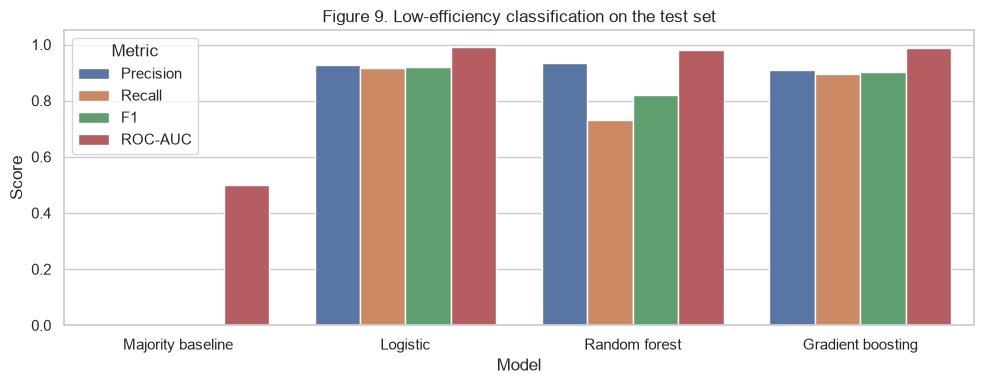

In [25]:
clf_dir = Path('outputs/step05')
clf_dir.mkdir(parents=True, exist_ok=True)
clf_plot = classification_results.melt(id_vars='Model', value_vars=['Precision', 'Recall', 'F1', 'ROC-AUC'], var_name='Metric', value_name='Score')
plt.figure(figsize=(10, 4))
sns.barplot(data=clf_plot, x='Model', y='Score', hue='Metric')
plt.ylim(0, 1.05)
plt.title('Figure 9. Low-efficiency classification on the test set')
plt.tight_layout()
plt.savefig(clf_dir / 'Fig9_Classification_Comparison.png', dpi=300)
plt.show()

## 24. Confusion matrix for the selected model

The vertical axis shows true classes and the horizontal axis shows predicted classes. The upper-right cell contains false positives, the lower-left cell false negatives, and the lower-right cell correctly identified low-efficiency orders.

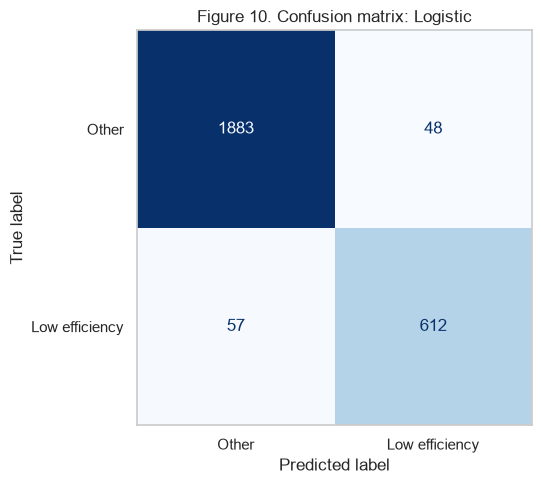

In [26]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_low_test, clf_predictions[selected_clf_name], display_labels=['Other', 'Low efficiency'], cmap='Blues', colorbar=False, ax=ax)
ax.grid(False)
plt.title(f'Figure 10. Confusion matrix: {selected_clf_name}')
plt.tight_layout()
plt.savefig(clf_dir / 'Fig10_Confusion_Matrix.png', dpi=300)
plt.show()

## 25. Precision-recall and ROC curves

The precision-recall curve shows the trade-off between precision and recall across thresholds. Its horizontal dashed line marks the positive-class proportion in the test set. The ROC curve shows the true-positive rate against the false-positive rate; the diagonal dashed line represents random ranking. Use these curves for evaluation, without adjusting the test classification threshold.

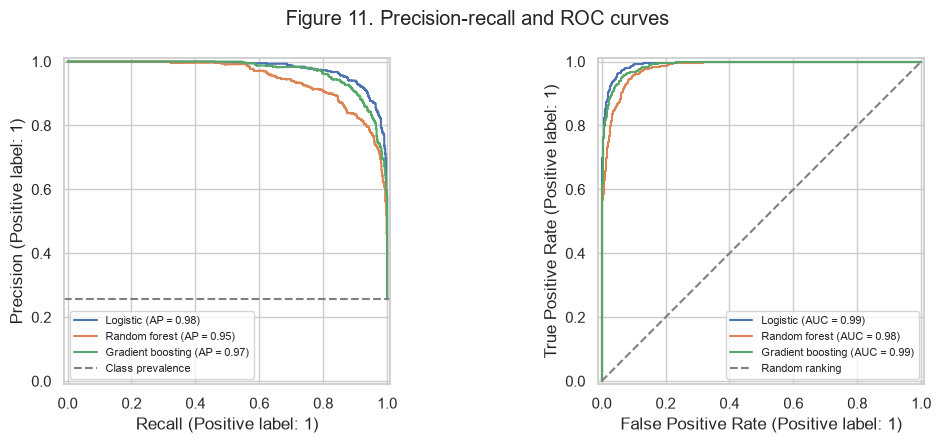

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name in ['Logistic', 'Random forest', 'Gradient boosting']:
    PrecisionRecallDisplay.from_predictions(y_low_test, clf_probabilities[name], name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_low_test, clf_probabilities[name], name=name, ax=axes[1])
axes[0].axhline(y_low_test.mean(), linestyle='--', color='grey', label='Class prevalence')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random ranking')
for ax in axes:
    ax.legend(fontsize=8)
fig.suptitle('Figure 11. Precision-recall and ROC curves')
plt.tight_layout()
plt.savefig(clf_dir / 'Fig11_PR_ROC_Curves.png', dpi=300)
plt.show()

## 26. Which factors contribute most to prediction?

Permutation importance shuffles one original test feature at a time and measures the decrease in ROC-AUC. Larger decreases indicate greater model reliance on the feature. Error bars show the standard deviation across five shuffles, not confidence intervals. Use these results only for interpretation, not to reselect models or remove features.

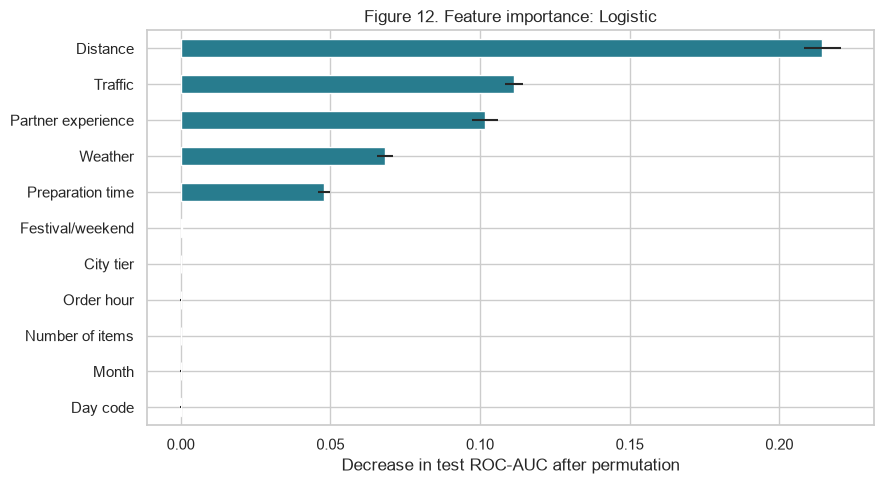

,Feature,AUC decrease,SD,Label
4,delivery_distance_km,0.2144,0.0062,Distance
6,traffic_level_score,0.1113,0.0029,Traffic
8,delivery_partner_experience_years,0.1016,0.0043,Partner experience
7,weather_severity_score,0.0683,0.0028,Weather
5,preparation_time_minutes,0.0479,0.0019,Preparation time
10,festival_or_weekend_flag,0.0003,0.0000,Festival/weekend
0,city_tier,0.0000,0.0000,City tier
1,order_hour,0.0000,0.0002,Order hour
9,number_of_items,0.0000,0.0000,Number of items
3,order_month,-0.0001,0.0001,Month


In [28]:
clf_importance = permutation_importance(clf_models[selected_clf_name], X_test, y_low_test, scoring='roc_auc', n_repeats=5, random_state=42, n_jobs=1)
clf_importance_table = pd.DataFrame({'Feature': features, 'AUC decrease': clf_importance.importances_mean, 'SD': clf_importance.importances_std})
clf_importance_table['Label'] = ['City tier', 'Order hour', 'Day code', 'Month', 'Distance', 'Preparation time', 'Traffic', 'Weather', 'Partner experience', 'Number of items', 'Festival/weekend']
clf_importance_table = clf_importance_table.sort_values('AUC decrease', ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
clf_importance_table.plot.barh(x='Label', y='AUC decrease', xerr='SD', color='#287c8e', legend=False, ax=ax)
ax.invert_yaxis()
ax.set(xlabel='Decrease in test ROC-AUC after permutation', ylabel='')
plt.title(f'Figure 12. Feature importance: {selected_clf_name}')
plt.tight_layout()
plt.savefig(clf_dir / 'Fig12_Classification_Importance.png', dpi=300)
plt.show()
test_predictions = pd.DataFrame({'order_id': test['order_id'],
                                 'actual_efficiency_score': test['delivery_efficiency_score'],
                                 'true_low_efficiency': y_low_test})
for name in clf_models:
    test_predictions[name + '_predicted'] = clf_predictions[name]
    test_predictions[name + '_probability'] = clf_probabilities[name]
test_predictions.to_csv(clf_dir / 'RQ3_Test_Predictions.csv', index=False)
clf_importance_table.to_csv(clf_dir / 'RQ3_Permutation_Importance.csv', index=False)

clf_importance_table.round(4)

## Interpretation of RQ3 results

The low-efficiency cutoff is the training-set 25th percentile, 46.9. There are 2,603 low-efficiency orders in the training set and 669 in the test set. Model parameters and the classification threshold are fixed in advance. Select the model by mean F1 across five training folds.

The selected model is **Logistic**. Its test precision is **0.927**, recall **0.915**, F1 **0.921**, ROC-AUC **0.992**, and AP **0.979**.
It correctly identifies 612 low-efficiency orders, misses 57, and flags 48 other orders incorrectly. It correctly identifies 1,883 other orders.
Although the majority-class baseline has 74.3% accuracy, its recall and F1 are both zero. Accuracy alone therefore conceals its failure to identify any low-efficiency orders.

### Main predictive factors

- Distance: mean test ROC-AUC decrease of 0.2144, with a standard deviation of 0.0062 across five shuffles.
- Traffic: mean test ROC-AUC decrease of 0.1113, with a standard deviation of 0.0029.
- Partner experience: mean test ROC-AUC decrease of 0.1016, with a standard deviation of 0.0043.
- Weather: mean test ROC-AUC decrease of 0.0683, with a standard deviation of 0.0028.
- Preparation time: mean test ROC-AUC decrease of 0.0479, with a standard deviation of 0.0019.

### Answer to RQ3 and interpretation limits

Under the specified prediction scenario in this synthetic dataset, the model can identify orders likely to meet the scoring-rule definition of low efficiency before delivery completion. Permutation importance describes the selected model's reliance on inputs. It does not measure causal effects and is not used to reselect features.

The efficiency score can be reproduced using a fixed formula involving actual time, traffic, weather, and experience, with a positive weight for experience. Importance therefore does not demonstrate that increasing experience necessarily shortens actual delivery time.

Actual delivery time, the efficiency score, and ETA are not prediction inputs. Test curves are not used to adjust thresholds. Step 6 examines the removal of preparation time, alternative efficiency quantiles, the inclusion of cancelled orders, and PDP/ICE explanations.

## Illustrative orders used in report Table 3

Select one true positive, one false negative, and one false positive. Within each group, sort by order ID and sample one order with random_state=42. Actual delivery time is included only for retrospective interpretation and is not a classification input. The probabilities are model outputs, not calibrated guarantees.

In [29]:
case_data = test[['order_id', 'delivery_efficiency_score', 'delivery_time_minutes',
                  'delivery_distance_km', 'traffic_level_score', 'preparation_time_minutes']].copy()
case_data['True low efficiency'] = y_low_test
case_data['Predicted low efficiency'] = clf_predictions[selected_clf_name]
case_data['Probability'] = clf_probabilities[selected_clf_name]
case_rows = []
for label, actual, predicted in [('A', 1, 1), ('B', 1, 0), ('C', 0, 1)]:
    group = case_data[(case_data['True low efficiency'] == actual) &
                      (case_data['Predicted low efficiency'] == predicted)]
    selected = group.sort_values('order_id').sample(1, random_state=42).copy()
    selected.insert(0, 'Case', label)
    case_rows.append(selected)
case_examples = pd.concat(case_rows)
case_examples[['Case', 'order_id', 'delivery_efficiency_score', 'Probability',
               'delivery_time_minutes', 'delivery_distance_km', 'traffic_level_score',
               'preparation_time_minutes']].round(6)

,Case,order_id,delivery_efficiency_score,Probability,delivery_time_minutes,delivery_distance_km,traffic_level_score,preparation_time_minutes
10905,A,231f4e70-9831-40e5-be0d-44284fa638b8,27.2,0.999987,151,33.357043,8.5,58
13377,B,019fd1c4-8453-49af-9034-074144bded86,46.7,0.123035,97,9.506507,1.0,60
3344,C,8ec6f157-c657-4f72-bcdf-07e1f6eae931,49.6,0.904137,109,29.682800,7.4,43


# Step 6: Sensitivity Analysis and PDP/ICE

Use Ridge and Logistic, selected through training-set cross-validation, without changing their parameters. Do not retune or replace the primary models using these test results. The three planned checks examine prediction information, the efficiency-label definition, and the inclusion of cancelled orders.

## 27. Remove actual preparation time

Keep the original training and test orders and the efficiency cutoff of 46.9. Remove only preparation time. Availability of the remaining inputs at an earlier stage remains an assumption; this experiment does not establish that every field is known when the order is placed.

In [30]:
best_reg = models[selected_name]
best_clf = clf_models[selected_clf_name]
early_features = [c for c in features if c != 'preparation_time_minutes']
early_numeric = [c for c in numeric if c != 'preparation_time_minutes']
early_preprocess = ColumnTransformer([
    ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categories),
    ('numeric', StandardScaler(), early_numeric),
    ('weekend', 'passthrough', ['festival_or_weekend_flag'])
])
early_reg = make_pipeline(clone(early_preprocess), Ridge(alpha=1.0))
early_clf = make_pipeline(clone(early_preprocess), LogisticRegression(C=1.0, max_iter=2000, random_state=42))
early_reg.fit(train[early_features], y_time_train)
early_clf.fit(train[early_features], y_low_train)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('category',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['city_tier', 'order_hour',
                                                   'order_day_of_week',
                                                   'order_month']),
                                                 ('numeric', StandardScaler(),
                                                  ['delivery_distance_km',
                                                   'traffic_level_score',
                                                   'weather_severity_score',
                                                   'delivery_partner_experience_years',
                                                   'number_of_items']),
                                          

## 28. Compare prediction information scenarios

Compare MAE for regression and F1 and ROC-AUC for classification. These are two information scenarios; test performance is not used to reselect the inputs.

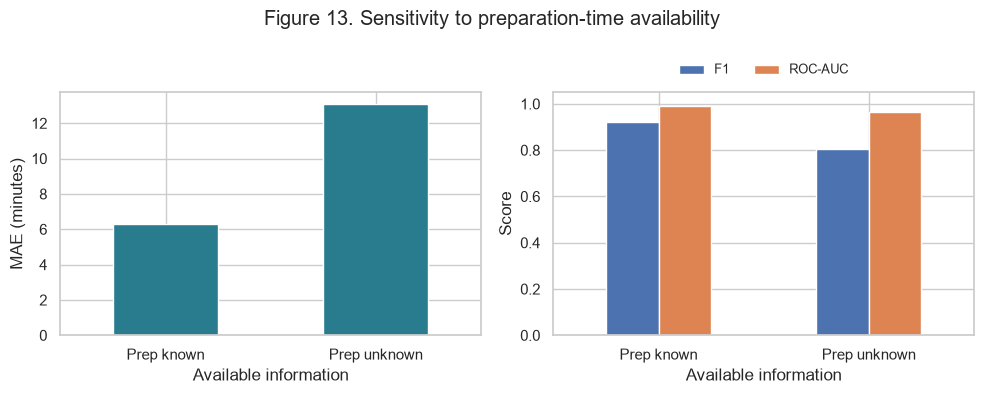

,Scenario,MAE,F1,ROC-AUC
0,Prep known,6.309,0.921,0.992
1,Prep unknown,13.096,0.806,0.966


In [31]:
stage_results = pd.DataFrame([
    {'Scenario': 'Prep known', 'MAE': mean_absolute_error(y_time_test, best_reg.predict(X_test)),
     'F1': f1_score(y_low_test, best_clf.predict(X_test)), 'ROC-AUC': roc_auc_score(y_low_test, best_clf.predict_proba(X_test)[:, 1])},
    {'Scenario': 'Prep unknown', 'MAE': mean_absolute_error(y_time_test, early_reg.predict(test[early_features])),
     'F1': f1_score(y_low_test, early_clf.predict(test[early_features])), 'ROC-AUC': roc_auc_score(y_low_test, early_clf.predict_proba(test[early_features])[:, 1])}
])
step6_dir = Path('outputs/step06')
step6_dir.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
stage_results.plot.bar(x='Scenario', y='MAE', color='#287c8e', legend=False, rot=0, ax=axes[0])
stage_results.plot.bar(x='Scenario', y=['F1', 'ROC-AUC'], rot=0, ax=axes[1])
axes[0].set(ylabel='MAE (minutes)', xlabel='Available information')
axes[1].set(ylabel='Score', xlabel='Available information', ylim=(0, 1.05))
axes[1].legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False, fontsize=9)
fig.suptitle('Figure 13. Sensitivity to preparation-time availability')
plt.tight_layout()
plt.savefig(step6_dir / 'Fig13_Prediction_Stage.png', dpi=300)
plt.show()
stage_results.to_csv(step6_dir / 'Sensitivity_Prediction_Stage.csv', index=False)
stage_results.round(3)

## 29. Change the efficiency quantile cutoff

Define labels using the training-set 20th, 25th, and 30th percentiles while keeping model parameters unchanged. Each cutoff is calculated from the training set only. Different cutoffs produce different positive-class sets, so this is a sensitivity check rather than a performance ranking of equivalent tasks.

In [32]:
quantile_rows = []
for q in [0.20, 0.25, 0.30]:
    cutoff = train['delivery_efficiency_score'].quantile(q)
    y_train_q = (train['delivery_efficiency_score'] <= cutoff).astype(int)
    y_test_q = (test['delivery_efficiency_score'] <= cutoff).astype(int)
    model_q = clone(best_clf).fit(X_train, y_train_q)
    predicted_q, probability_q = model_q.predict(X_test), model_q.predict_proba(X_test)[:, 1]
    quantile_rows.append({'Quantile': q, 'Cutoff': cutoff, 'Test positive': y_test_q.sum(),
                          'Precision': precision_score(y_test_q, predicted_q), 'Recall': recall_score(y_test_q, predicted_q),
                          'F1': f1_score(y_test_q, predicted_q), 'ROC-AUC': roc_auc_score(y_test_q, probability_q)})
quantile_results = pd.DataFrame(quantile_rows)
quantile_results.round(3)

,Quantile,Cutoff,Test positive,Precision,Recall,F1,ROC-AUC
0,0.20,44.0,522,0.881,0.906,0.893,0.991
1,0.25,46.9,669,0.927,0.915,0.921,0.992
2,0.30,49.8,814,0.928,0.920,0.924,0.992


## 30. Include cancelled orders in training and evaluation

Preserve the training/test membership of every original non-cancelled order. Split cancelled orders separately into 80% training and 20% test subsets, then combine the corresponding groups. This prevents original test orders from entering training. Keep the primary reference cutoff of 46.9 fixed so that the label rule does not change with cohort scope.

In [33]:
cancelled = data[data['cancellation_flag'] == True]
cancel_train, cancel_test = train_test_split(cancelled, test_size=0.2, random_state=42)
train_all = pd.concat([train, cancel_train])
test_all = pd.concat([test, cancel_test])
reg_all = clone(best_reg).fit(train_all[features], train_all['delivery_time_minutes'])
y_low_all = (train_all['delivery_efficiency_score'] <= threshold).astype(int)
clf_all = clone(best_clf).fit(train_all[features], y_low_all)

## 31. Distinguish the common and expanded test sets

The first comparison uses the same 2,600 non-cancelled test orders to examine the effect of adding training records. The second evaluates an expanded test set that includes cancelled records. Because the populations differ, do not rank the metrics directly across the two test sets. Cancelled orders have time and score values in the CSV; use them only for this synthetic-data sensitivity check.

In [34]:
cohort_rows = [{'Evaluation': 'Primary / original test', 'Train n': len(train), 'Test n': len(test),
                'MAE': stage_results.iloc[0]['MAE'], 'F1': stage_results.iloc[0]['F1'], 'ROC-AUC': stage_results.iloc[0]['ROC-AUC']}]
for name, evaluation in [('Expanded / original test', test), ('Expanded / expanded test', test_all)]:
    labels = (evaluation['delivery_efficiency_score'] <= threshold).astype(int)
    cohort_rows.append({'Evaluation': name, 'Train n': len(train_all), 'Test n': len(evaluation),
                        'MAE': mean_absolute_error(evaluation['delivery_time_minutes'], reg_all.predict(evaluation[features])),
                        'F1': f1_score(labels, clf_all.predict(evaluation[features])),
                        'ROC-AUC': roc_auc_score(labels, clf_all.predict_proba(evaluation[features])[:, 1])})
cohort_results = pd.DataFrame(cohort_rows)
cohort_results.round(3)

,Evaluation,Train n,Test n,MAE,F1,ROC-AUC
0,Primary / original test,10397,2600,6.309,0.921,0.992
1,Expanded / original test,11999,2600,6.312,0.923,0.992
2,Expanded / expanded test,11999,3001,6.349,0.923,0.992


## 32. PDP and ICE: how do predictions respond to feature changes?

Partial dependence plots (PDP) show predictions averaged over the other inputs in a reference sample. Individual conditional expectation (ICE) curves show the corresponding response for individual orders. Use 1,000 randomly sampled training orders as the reference and plot 25 ICE curves per panel. Continuous features use grids between the 5th and 95th percentiles; experience uses its observed discrete values.

These plots explain the primary classifier and do not show real causal effects. Logistic has no explicit interaction terms, and differences between ICE curves do not by themselves establish interactions.

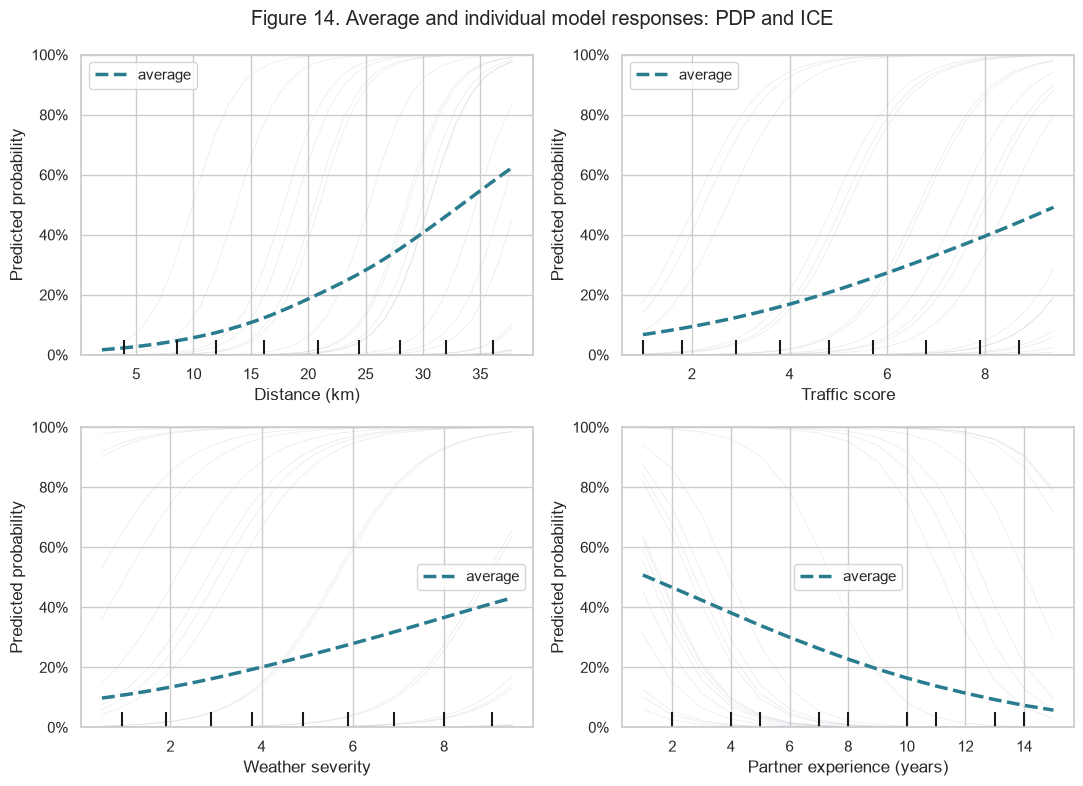

In [35]:
from sklearn.inspection import PartialDependenceDisplay, partial_dependence
from matplotlib.ticker import PercentFormatter

reference = X_train.sample(1000, random_state=42)
pdp_features = ['delivery_distance_km', 'traffic_level_score', 'weather_severity_score', 'delivery_partner_experience_years']
reference = reference.astype({column: float for column in pdp_features})
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
pdp_display = PartialDependenceDisplay.from_estimator(best_clf, reference, pdp_features, kind='both', subsample=25, grid_resolution=30, random_state=42, method='brute', response_method='predict_proba', n_jobs=1, ax=axes, pd_line_kw={'color': '#287c8e', 'linewidth': 2.5}, ice_lines_kw={'color': '#b8c2cc', 'alpha': 0.35})
for ax, label in zip(axes.ravel(), ['Distance (km)', 'Traffic score', 'Weather severity', 'Partner experience (years)']):
    ax.set(xlabel=label, ylabel='Predicted probability', ylim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('Figure 14. Average and individual model responses: PDP and ICE')
plt.tight_layout()
plt.savefig(step6_dir / 'Fig14_PDP_ICE.png', dpi=300)
plt.show()

## 33. Two-dimensional PDP for distance and traffic

Vary distance and traffic together and average over the other inputs in the same training reference sample. Colour shows mean predicted probability, not evidence of a statistical interaction or real operational effects. Use the plot to interpret model responses, not to select models or adjust thresholds.

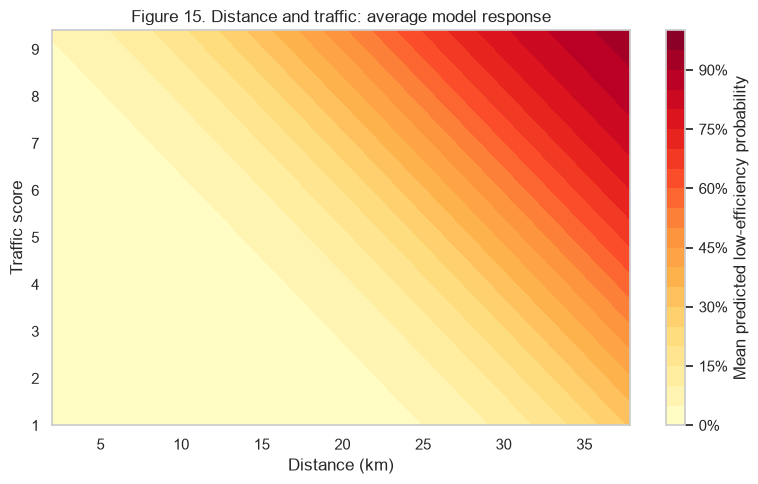

In [36]:
pdp_two = partial_dependence(best_clf, reference, ['delivery_distance_km', 'traffic_level_score'], method='brute', response_method='predict_proba', grid_resolution=30)
distance_grid, traffic_grid = pdp_two['grid_values']
plt.figure(figsize=(8, 5))
plt.contourf(distance_grid, traffic_grid, pdp_two['average'][0].T, levels=[i / 20 for i in range(21)], cmap='YlOrRd')
plt.colorbar(label='Mean predicted low-efficiency probability', format=PercentFormatter(1))
plt.xlabel('Distance (km)')
plt.ylabel('Traffic score')
plt.title('Figure 15. Distance and traffic: average model response')
plt.tight_layout()
plt.savefig(step6_dir / 'Fig15_Two_Dimensional_PDP.png', dpi=300)
plt.show()

## 34. Check the fixed structure of the efficiency score

Use a simple expression to check the earlier finding and explain the association between experience and the efficiency score. The expression uses actual delivery time only to check the data definition and is never added to the prediction inputs. Numerical agreement does not mean that the original author's generation code is available.

In [37]:
reconstructed = (100 - 0.4 * data['delivery_time_minutes'] - 2 * data['traffic_level_score'] - 1.5 * data['weather_severity_score'] + 1.8 * data['delivery_partner_experience_years']).clip(0, 100).round(1)
print('Matching scores:', (reconstructed == data['delivery_efficiency_score']).sum(), '/', len(data))
print('Maximum absolute difference:', (reconstructed - data['delivery_efficiency_score']).abs().max())

Matching scores: 15000 / 15000
Maximum absolute difference: 0.0


## Interpretation of Step 6 results

### Sensitivity to prediction information

Removing actual preparation time increases test MAE from 6.309 to 13.096 minutes. Classification F1 decreases from 0.921 to 0.806 and ROC-AUC from 0.992 to 0.966. The stronger primary results therefore depend on preparation time being known.

### Sensitivity to the label cutoff

At the training-set 20th, 25th, and 30th percentiles, ROC-AUC ranges from 0.991 to 0.992 and F1 from 0.893 to 0.924. The positive-class sets differ, so a higher score for one task does not establish a better model for an equivalent task.

### Inclusion of cancelled orders

The expanded training set contains 11,999 records. On the original 2,600 non-cancelled test orders, MAE is 6.312, F1 is 0.923, and ROC-AUC is 0.992. On the expanded test set of 3,001 records including cancelled orders, MAE is 6.349, F1 is 0.923, and ROC-AUC is 0.992.

This comparison preserves the original non-cancelled split and the reference cutoff of 46.9. Original test orders do not enter the expanded training set. The CSV provides time and score values for cancelled records, but these do not establish that those orders actually completed delivery.

### PDP and ICE

Figure 14 shows higher mean predicted low-efficiency probabilities as distance, traffic, and weather scores increase, and lower probabilities as experience increases. Figure 15 shows the mean model response as distance and traffic vary together. These curves are not causal effects and do not establish explicit interactions in Logistic.

The fixed efficiency expression exactly reproduces all 15,000 records, with a maximum absolute difference of zero. Interpret the relationship between experience and predicted efficiency in light of this scoring rule.

### Connecting the three research questions

RQ1 associations, RQ2 time prediction, and RQ3 low-efficiency identification form a consistent analysis of simulated data. Distance and preparation time are important for delivery time, while environmental conditions and experience are also directly linked to the efficiency score. The methods demonstrate prediction and interpretation workflows. Conclusions remain limited by the synthetic generation process, input availability, and efficiency definition, and do not establish causal dispatch recommendations for real platforms.